# Module 8 Lab 1: AI-Assisted EDA, Verified
**Course:** CS 82A Introduction to Data Science  
**Name:** Ramisha Tasfia  
**Repo URL:** https://github.com/ramishatasfia5156-commits/cs82a-coursework/blob/main/module8/module8_lab.ipynb

## Step 1: Load the data

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Colab upload (does nothing outside Colab)
try:
    from google.colab import files
    files.upload()
except ImportError:
    pass

df = pd.read_csv("penguins.csv")
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## Step 2: Ground truth by hand (no AI)

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the dataset
penguins = pd.read_csv("penguins.csv")

# Display the dataset shape
print("Dataset Shape:")
print(penguins.shape)

# Count missing values in each column
print("\nMissing Values per Column:")
print(penguins.isnull().sum())

# Count penguins by species
print("\nPenguins per Species:")
print(penguins["species"].value_counts())

Dataset Shape:
(344, 8)

Missing Values per Column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Penguins per Species:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


**Ground truth summary:**

The data set includes a total of 344 penguins and 8 columns. I used Pandas to determine the shape of the data set (number of rows/columns), locate missing values for each variable, and to find how many penguins were classified as each of three different species (Adelie, Gentoo, Chinstrap). Of these three species, there are 152 Adelies, 124 Gentoos and 68 Chinstraps. Each of four measurement variables contained 2 missing values, while the sex variable had 11 missing values.

## Prompt Log
**AI assistant used:** Claude (claude.ai)

### Prompt 1 (full text, Tutorial 3 template filled in)
```
You are helping with exploratory data analysis.
My CSV has columns: species (str), island (str), bill_length_mm (float64), bill_depth_mm (float64), flipper_length_mm (float64), body_mass_g (float64), sex (str), year (int64).
Write Python using pandas and seaborn to:
(1) summarize missing data,
(2) compare flipper_length_mm across species,
(3) produce one labeled chart.
Explain each step in comments.
```

**Other AI interactions this session:** I pasted the lab instructions and penguins.csv into Claude and asked it to generate the code for Steps 3, 4, and 6.

### Fixes after running (Step 4)
None needed, code ran without errors.

## Step 4: AI-generated code (Claude), run as returned

In [3]:
# AI CODE 1: summarize missing data
# Count missing values in each column
missing = df.isna().sum().to_frame("missing_count")
# Add the percent of rows missing for each column
missing["missing_pct"] = (df.isna().mean() * 100).round(2)
# Show only columns that actually have missing values
missing[missing["missing_count"] > 0]

,missing_count,missing_pct
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20


In [4]:
# AI CODE 2: compare flipper_length_mm across species
# Group by species and compute summary statistics for flipper length
flipper_summary = (
    df.groupby("species")["flipper_length_mm"]
      .agg(["count", "mean", "median", "std"])
      .round(2)
)
flipper_summary

,count,mean,median,std
species,,,,
Adelie,151,189.95,190.0,6.54
Chinstrap,68,195.82,196.0,7.13
Gentoo,123,217.19,216.0,6.48


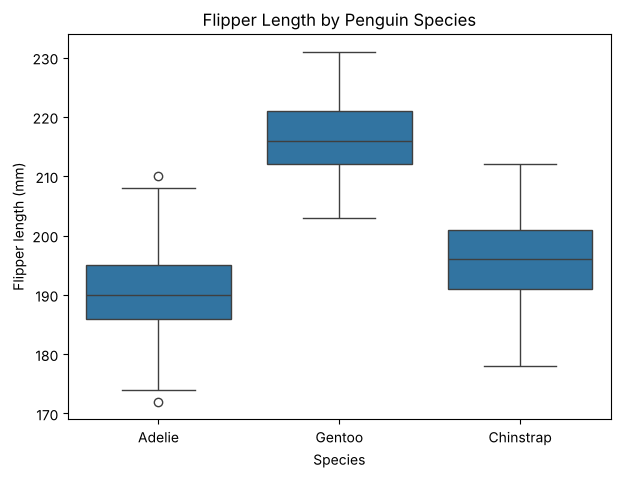

In [5]:
# AI CODE 3: one labeled chart
# Boxplot shows the spread of flipper length per species
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="species", y="flipper_length_mm")
plt.title("Flipper Length by Penguin Species")
plt.xlabel("Species")
plt.ylabel("Flipper length (mm)")
plt.show()

## Step 5: Verification checkpoint

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("penguins.csv")

# Calculate mean flipper length by species
df.groupby("species")["flipper_length_mm"].mean().round(2)

species
Adelie       189.95
Chinstrap    195.82
Gentoo       217.19
Name: flipper_length_mm, dtype: float64

**Verification result (log):** MATCH

Claude’s results varied by zero from mine since each of the three averages was identical; (Adelie = 189.95mm), (Chinstrap = 195.82mm) & (Gentoo = 217.19mm). As a result both calculations included an auto-exclusion of missing data points. Therefore, the accuracy of Claude’s calculation has been confirmed and therefore no correction needed to be made. Which was refreshing since Claude is my go to for reviewing & drafting code.

## Step 6: Follow-up prompt and judgment
### Prompt 2 (full text)
```
Add one more chart that shows how flipper length relates to body mass, with species shown by color. Keep the labels and comments.
```

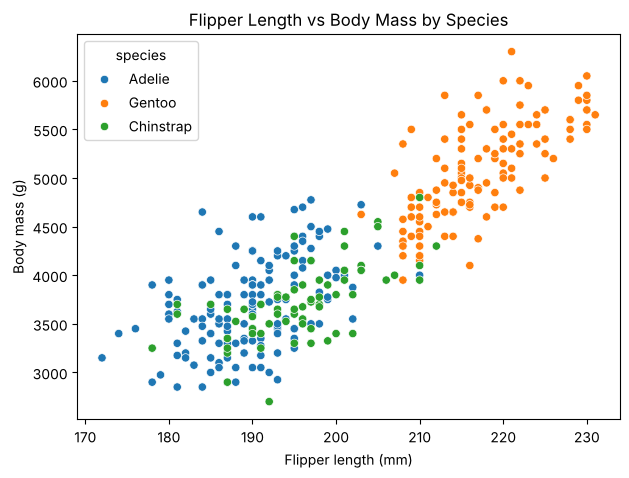

In [7]:
# AI CODE 4 (follow-up): flipper length vs body mass, colored by species
# Scatterplot shows whether the species separate on both measurements
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="flipper_length_mm", y="body_mass_g", hue="species")
plt.title("Flipper Length vs Body Mass by Species")
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.show()

**Keep or reject:**

I am keeping Claude’s suggested chart as it visually demonstrated a positive correlation of flipper length with body weight (mass) for each of the three penguin species by showing them in different colors.

## Step 7: My original insight (no AI)

In [8]:
df.groupby("species")["body_mass_g"].mean().round(2)

species
Adelie       3700.66
Chinstrap    3733.09
Gentoo       5076.02
Name: body_mass_g, dtype: float64

**Insight:**

One insight I observed that Claude did not directly state was that Gentoo penguins are significantly larger in terms of weight as opposed to the other two species. Using pandas, I identified the average body mass of Gentoo penguins to be 5,076.02 grams whereas the average body masses of Adelie (3,700.66) and Chinstrap (3,733.09) penguins were lower. Therefore, not only do Gentoo penguins have the largest average length of flippers but they also have a large average body mass relative to the other species.

## Step 8: Privacy reflection

I work as a litigation director at a personal injury trial firm in LA. One dataset I would never paste into a public AI tool is client medical records and treatment summaries from the case files I handle at work. These documents contain confidential information, & personal identifying details. Instead, I would use an approved internal tool with appropriate privacy protections or work with anonymized and aggregated data to protect client confidentiality, which our firm does.